<a href="https://colab.research.google.com/github/naylaakas/PembelajaranMesin-2026/blob/main/JS07/datasetPBL/TugasPraktikum.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# Load kedua dataset asli dan gabungkan melalui 'cafe_id'
df_cafes = pd.read_csv('cafes.csv')
df_reviews = pd.read_csv('reviews.csv')

df = pd.merge(
    df_reviews,
    df_cafes,
    on='cafe_id',
    how='left',
    suffixes=('_review', '_cafe')
)

df.head()

,review_id,cafe_id,author_name,rating_review,text,published_at,likes,scraped_at_review,name,address,latitude,longitude,rating_cafe,review_count,categories,phone,website,scraped_at_cafe,source_query
0,21314615-664d-438a-9f68-142f5b13f4c9,ba4b512c-fa2d-4959-8384-8570c81121ec,Alicia K. Taruli Manurung,5.0,Hore!,11 menit lalu,0,2026-10-11T13:54:49.423310,ARTE COFFEE & EATERY,"Jl. Semeru No.80, Oro-oro Dowo, Kec. Klojen, K...",-7.972556,112.622708,4.7,528,['Kedai Kopi'],0821-3299-9938,instagram.com,2026-10-11T13:54:39.597643,cafe Kota Malang
1,ec085c18-dced-4c23-8a65-4f71f93ed181,ba4b512c-fa2d-4959-8384-8570c81121ec,seobchwi fb,5.0,Pelayanan bagus dan ramah apalagi barista yg p...,14 menit lalu,0,2026-10-11T13:54:49.622536,ARTE COFFEE & EATERY,"Jl. Semeru No.80, Oro-oro Dowo, Kec. Klojen, K...",-7.972556,112.622708,4.7,528,['Kedai Kopi'],0821-3299-9938,instagram.com,2026-10-11T13:54:39.597643,cafe Kota Malang
2,6f1a2d5a-01c1-4fc9-8cfb-c4f5c8f58ec1,ba4b512c-fa2d-4959-8384-8570c81121ec,Nico Julianda,5.0,"comfort places for everything i did, mulai dar...",22 menit lalu,0,2026-10-11T13:54:49.854029,ARTE COFFEE & EATERY,"Jl. Semeru No.80, Oro-oro Dowo, Kec. Klojen, K...",-7.972556,112.622708,4.7,528,['Kedai Kopi'],0821-3299-9938,instagram.com,2026-10-11T13:54:39.597643,cafe Kota Malang
3,fd86734a-dcef-4f6d-8251-e47b203c0199,ba4b512c-fa2d-4959-8384-8570c81121ec,nazira parsa_04,5.0,"minumannya enak"", tempatnya comfy. worth to try",23 menit lalu,0,2026-10-11T13:54:49.967848,ARTE COFFEE & EATERY,"Jl. Semeru No.80, Oro-oro Dowo, Kec. Klojen, K...",-7.972556,112.622708,4.7,528,['Kedai Kopi'],0821-3299-9938,instagram.com,2026-10-11T13:54:39.597643,cafe Kota Malang
4,cdeda318-e583-4473-9fd0-4e4b48b56e16,ba4b512c-fa2d-4959-8384-8570c81121ec,dulkamdi dul,5.0,"kopian 24jam enak banget kalau dibuat wfc, tem...",28 menit lalu,0,2026-10-11T13:54:50.058719,ARTE COFFEE & EATERY,"Jl. Semeru No.80, Oro-oro Dowo, Kec. Klojen, K...",-7.972556,112.622708,4.7,528,['Kedai Kopi'],0821-3299-9938,instagram.com,2026-10-11T13:54:39.597643,cafe Kota Malang


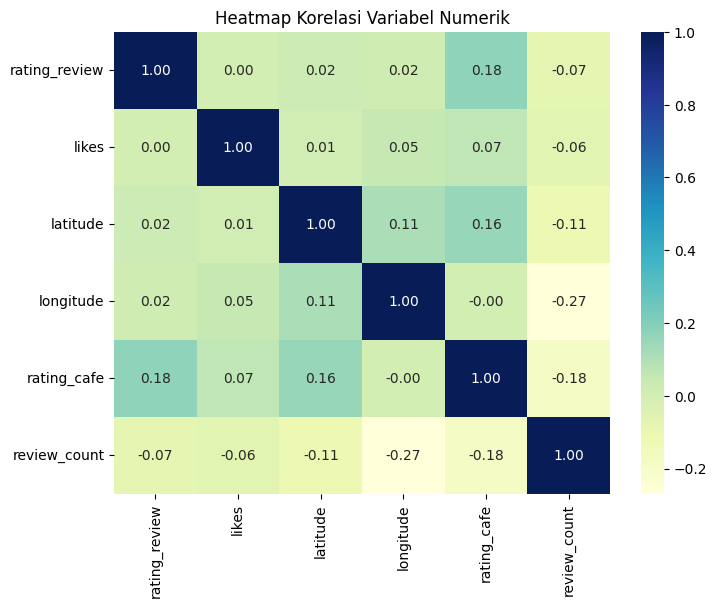

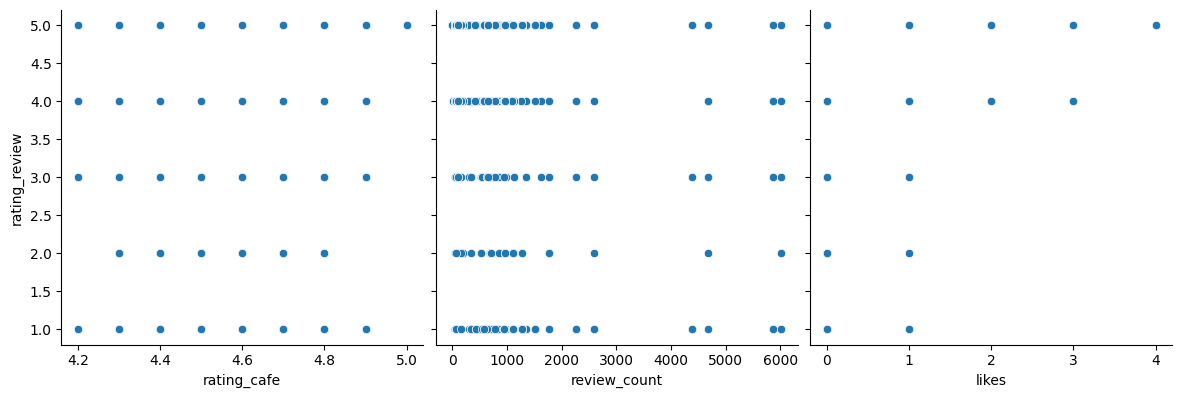

In [2]:
# Visualisasi korelasi antar variabel numerik
plt.figure(figsize=(8, 6))
sns.heatmap(df.corr(numeric_only=True), cmap="YlGnBu", annot=True, fmt=".2f")
plt.title("Heatmap Korelasi Variabel Numerik")
plt.show()

# Visualisasi hubungan beberapa fitur utama terhadap target rating_review
sns.pairplot(
    df,
    x_vars=['rating_cafe', 'review_count', 'likes'],
    y_vars='rating_review',
    height=4,
    aspect=1,
    kind='scatter'
)
plt.show()

In [3]:
# 1. Identifikasi variabel bebas (X) dan target (y)
num_features = ['rating_cafe', 'review_count', 'likes', 'latitude', 'longitude']
cat_features = ['categories']

X = df[num_features + cat_features]
y = df['rating_review']

# 2. Bagi dataset menjadi data latih (80%) dan data uji (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 3. Feature Scaling untuk fitur numerik & OneHotEncoding untuk fitur kategorikal
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_features),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), cat_features)
    ]
)

X_train_scaled = preprocessor.fit_transform(X_train)
X_test_scaled = preprocessor.transform(X_test)

In [4]:
# 4. Buat model Multiple Linear Regression menggunakan Scikit-Learn
model = LinearRegression()

# 5. Latih model pada data latih dan lakukan prediksi pada data uji
model.fit(X_train_scaled, y_train)
y_pred = model.predict(X_test_scaled)

In [5]:
# 6. Evaluasi model
r2 = r2_score(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)

print("Hasil Evaluasi Multiple Linear Regression:")
print(f"R-squared (R2) : {r2:.4f}")
print(f"MSE            : {mse:.4f}")
print(f"RMSE           : {rmse:.4f}")
print(f"MAE            : {mae:.4f}")

Hasil Evaluasi Multiple Linear Regression:
R-squared (R2) : 0.0433
MSE            : 1.0758
RMSE           : 1.0372
MAE            : 0.6790


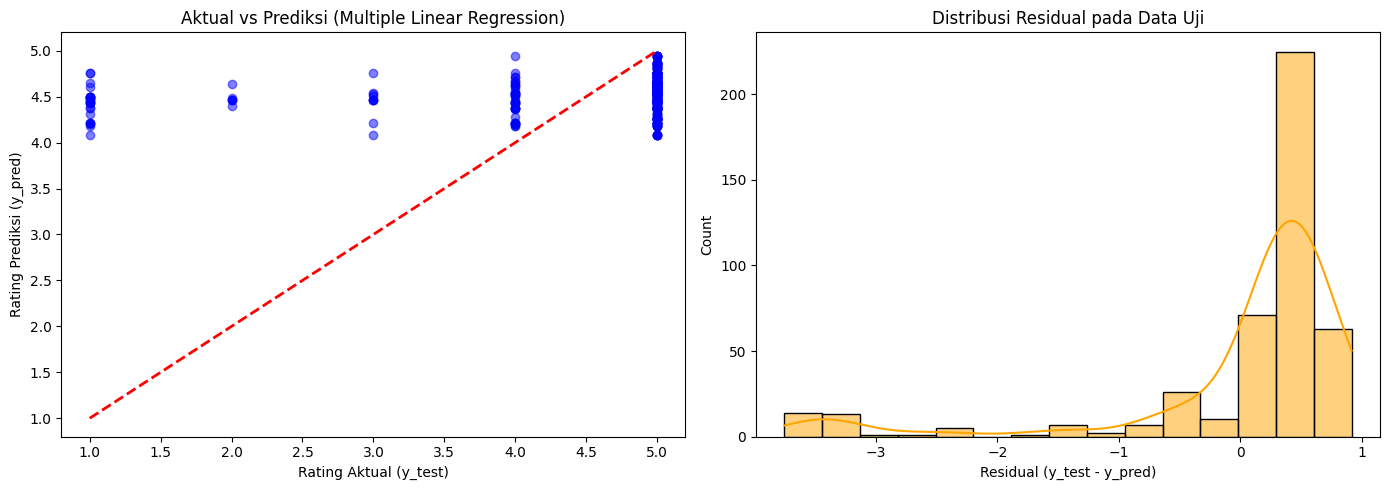

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Nilai Aktual vs Nilai Prediksi
axes[0].scatter(y_test, y_pred, alpha=0.5, color='blue')
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
axes[0].set_xlabel('Rating Aktual (y_test)')
axes[0].set_ylabel('Rating Prediksi (y_pred)')
axes[0].set_title('Aktual vs Prediksi (Multiple Linear Regression)')

# Plot 2: Distribusi Residual (Error)
residual = y_test - y_pred
sns.histplot(residual, bins=15, kde=True, ax=axes[1], color='orange')
axes[1].set_xlabel('Residual (y_test - y_pred)')
axes[1].set_title('Distribusi Residual pada Data Uji')

plt.tight_layout()
plt.show()